In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, r2_score

In [10]:
df = load_diabetes(as_frame=True).frame
print(df.head())
x, y = df.drop(columns='target'), df['target']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


In [3]:
models = {
    'Linear': LinearRegression(),
    'Ridge': RidgeCV(np.logspace(-3, 3, 50), cv=50),
    'Lasso': LassoCV(cv=50, max_iter=10000)
}
preds, coefs = {},{}

In [4]:
print(f"{'Name':<10}{'MSE':<12}{'R2':<12}")
print("-"*40)
for name, model in models.items():
    model.fit(x_train, y_train)
    preds[name] = model.predict(x_test)
    coefs[name] = model.coef_
    mse = mean_squared_error(y_test, preds[name])
    r2 = r2_score(y_test, preds[name])
    print(f"{name:<10}{mse:<12.4f}{r2:<10.2f}")

Name      MSE         R2          
----------------------------------------
Linear    2900.1936   0.45      
Ridge     2883.6326   0.46      
Lasso     2882.5715   0.46      


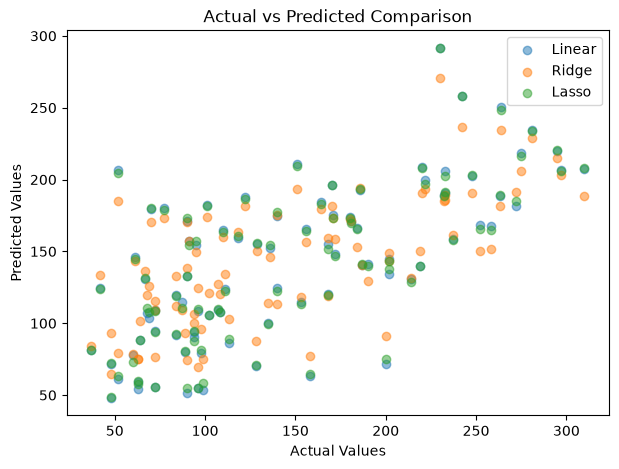

In [5]:
plt.figure(figsize=(7,5))
for name, pred in preds.items():
    plt.scatter(y_test, pred, alpha=0.5, label=name)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Comparison")
plt.legend()
plt.show()


Coefficients :
          Linear       Ridge       Lasso
age   37.904021   45.110675   36.726944
sex -241.964362 -142.897598 -236.070630
bmi  542.428759  408.112166  548.298848
bp   347.703844  266.090651  343.153344
s1  -931.488846  -39.498093 -574.795253
s2   518.062277  -71.295818  244.414677
s3   163.419983 -181.237589    0.000000
s4   275.317902  135.847750  215.112832
s5   736.198859  311.779956  603.991260
s6    48.670657  107.999614   49.626795


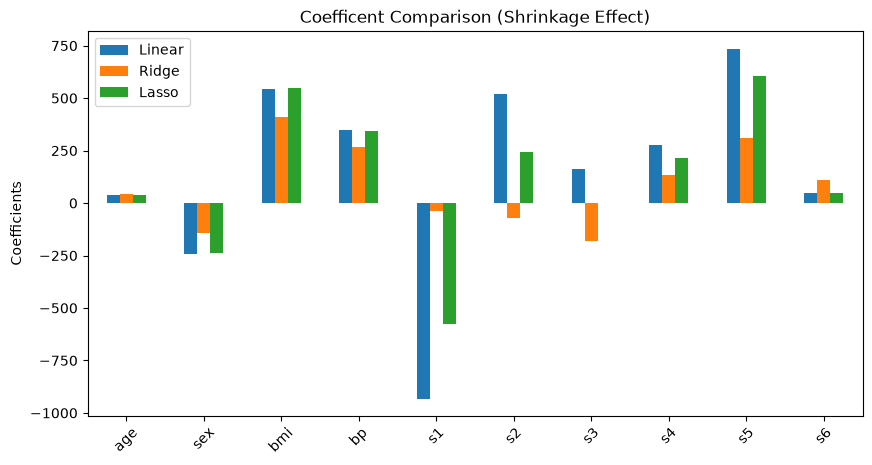

In [8]:
coef_df = pd.DataFrame(coefs, index=x.columns)
print("\nCoefficients :\n", coef_df)
coef_df.plot(kind='bar', figsize=(10,5), rot=45)
plt.title("Coefficent Comparison (Shrinkage Effect)")
plt.ylabel("Coefficients")
plt.legend()
plt.show()

In [9]:
print("Best Alpha Values")
print("Ridge Alpha : ", models["Ridge"].alpha_)
print("Lasso Alpha : ", models["Lasso"].alpha_)

Best Alpha Values
Ridge Alpha :  0.3727593720314938
Lasso Alpha :  0.006338163256215285
